In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0000.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0001.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0002.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0003.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0004.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0005.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0006.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0007.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0008.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0009.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id10_0000.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id10_0001.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id10_0002.mp4
/kaggle/input/

In [2]:
!pip install "setuptools<82"

In [10]:
# 1. Roll pip back to the version Kaggle shipped (pre-import trick, since 26.3 is the broken one)
!python -c "import importlib.metadata._adapters, sys, runpy; sys.argv=['pip','install','-q','pip==26.2.2']; runpy.run_module('pip', run_name='__main__')"
!pip --version

# 2. Install without pinned deps (no pip upgrade, no Pillow line)
!pip install -q --no-deps facenet-pytorch grad-cam ttach

pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)


In [17]:
import torch, torchvision, PIL, numpy, requests, tqdm
import cv2, sklearn, matplotlib
from facenet_pytorch import MTCNN, InceptionResnetV1
from pytorch_grad_cam import GradCAM
print("All imports OK")

All imports OK


In [18]:
!python -c "import importlib.metadata._adapters, sys, runpy; sys.argv=['pip','install','-q','--no-deps','facenet-pytorch','grad-cam','ttach']; runpy.run_module('pip', run_name='__main__')"

In [19]:
!python -c "import importlib.metadata._adapters, sys, runpy; sys.argv=['pip','install','-q','pip<26.3']; runpy.run_module('pip', run_name='__main__')"

In [20]:
# 1. Install (don't upgrade pip; keep Kaggle's torch/Pillow)
!pip install -q --no-deps facenet-pytorch grad-cam ttach

# 2. Verify GPU availability and dataset folder paths
import os
import torch

print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))

for root, dirs, files in os.walk("/kaggle/input"):
    mp4_files = [f for f in files if f.endswith(".mp4")]
    if len(mp4_files) > 0:
        print(f"Found {len(mp4_files)} videos in -> {root}")

GPU Available: True
Device Name: Tesla T4
Found 590 videos in -> /kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real
Found 5639 videos in -> /kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-synthesis
Found 300 videos in -> /kaggle/input/datasets/reubensuju/celeb-df-v2/YouTube-real


In [21]:
import cv2
import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset
from facenet_pytorch import MTCNN
from torchvision import transforms

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Initialize MTCNN for face cropping
mtcnn = MTCNN(image_size=224, margin=20, keep_all=False, post_process=False, device=device)
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

# Video face extraction function
def extract_face_sequence(video_path, num_frames=16):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        cap.release()
        return torch.zeros((num_frames, 3, 224, 224))

    frame_indices = np.linspace(0, total_frames - 1, num_frames, dtype=int)
    faces = []

    for idx in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if not ret:
            continue
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(rgb_frame)
        
        with torch.no_grad():
            face_tensor = mtcnn(pil_img)
            
        if face_tensor is not None:
            face_tensor = normalize(face_tensor.cpu() / 255.0)
            faces.append(face_tensor)
        else:
            faces.append(faces[-1].clone() if len(faces) > 0 else torch.zeros((3, 224, 224)))

    cap.release()
    while len(faces) < num_frames:
        faces.append(faces[-1].clone() if len(faces) > 0 else torch.zeros((3, 224, 224)))

    return torch.stack(faces[:num_frames])

# Define the missing Custom Dataset Class
class DeepfakeVideoDataset(Dataset):
    def __init__(self, video_paths, labels):
        self.video_paths = video_paths
        self.labels = labels

    def __len__(self):
        return len(self.video_paths)

    def __getitem__(self, idx):
        seq = extract_face_sequence(self.video_paths[idx], num_frames=16)
        label = torch.tensor(self.labels[idx], dtype=torch.float32)
        return seq, label

print("DeepfakeVideoDataset class defined successfully!")

DeepfakeVideoDataset class defined successfully!


In [26]:
import glob
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

# 1. Load exact video paths based on your Kaggle output
real_videos = glob.glob("/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/*.mp4")[:200]
fake_videos = glob.glob("/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-synthesis/*.mp4")[:200]

print(f"Loaded {len(real_videos)} Real and {len(fake_videos)} Fake videos.")

all_paths = real_videos + fake_videos
all_labels = [0] * len(real_videos) + [1] * len(fake_videos)

# 2. Split data into training (80%) and validation (20%) sets
train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_paths, all_labels, test_size=0.2, stratify=all_labels, random_state=42
)

# 3. Create Custom Dataset instances
train_dataset = DeepfakeVideoDataset(train_paths, train_labels)
val_dataset = DeepfakeVideoDataset(val_paths, val_labels)

# 4. Initialize DataLoaders (FIXED: num_workers=0 to avoid CUDA multiprocessing error)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=0)

print(f"Total training batches: {len(train_loader)} | Total validation batches: {len(val_loader)}")

Loaded 200 Real and 200 Fake videos.
Total training batches: 80 | Total validation batches: 20


In [27]:
import torch.nn as nn
import torchvision.models as models

# 1. Define Dual Attention (CBAM) - Focuses on eyes, mouth, and jawline
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))
        return x * self.sigmoid(avg_out + max_out)

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()
        self.conv1 = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        x_cat = torch.cat([avg_out, max_out], dim=1)
        return x * self.sigmoid(self.conv1(x_cat))

class CBAM(nn.Module):
    def __init__(self, in_planes, ratio=16, kernel_size=7):
        super(CBAM, self).__init__()
        self.ca = ChannelAttention(in_planes, ratio)
        self.sa = SpatialAttention(kernel_size)

    def forward(self, x):
        x = self.ca(x)
        x = self.sa(x)
        return x

# 2. Define the Complete Video Pipeline: ResNeXt-50 -> CBAM -> BiLSTM
class VideoDeepfakeModel(nn.Module):
    def __init__(self, lstm_hidden=256):
        super(VideoDeepfakeModel, self).__init__()
        
        # Load Pre-trained ResNeXt-50 (32x4d) and remove final FC layers
        weights = models.ResNeXt50_32X4D_Weights.DEFAULT
        backbone = models.resnext50_32x4d(weights=weights)
        self.cnn_backbone = nn.Sequential(*list(backbone.children())[:-2])
        
        # Add Dual Attention mechanism
        self.cbam = CBAM(in_planes=2048)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        
        # 1-Layer BiLSTM to catch frame-to-frame flickering
        self.bilstm = nn.LSTM(
            input_size=2048,
            hidden_size=lstm_hidden,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )
        
        # Temporal frame attention for Explainable AI (Line Chart)
        self.frame_attention = nn.Linear(lstm_hidden * 2, 1)
        
        # Final Classification Layer (Real vs Fake)
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(lstm_hidden * 2, 1)
        )

    def forward(self, x):
        # Input shape: (Batch, Seq_Len=16, Channels=3, H=224, W=224)
        b, seq_len, c, h, w = x.shape
        x = x.view(b * seq_len, c, h, w)
        
        # Process through CNN and CBAM
        feat_map = self.cnn_backbone(x)
        att_map = self.cbam(feat_map)
        pooled = self.global_pool(att_map)
        
        # Reshape for BiLSTM
        seq_features = pooled.view(b, seq_len, -1)
        lstm_out, _ = self.bilstm(seq_features)
        
        # Calculate attention weights per frame
        att_weights = torch.softmax(self.frame_attention(lstm_out), dim=1)
        
        # Generate final representation and logits
        video_representation = torch.sum(lstm_out * att_weights, dim=1)
        logits = self.classifier(video_representation)
        
        return logits, att_weights.squeeze(-1)

print("VideoDeepfakeModel architecture loaded successfully!")

VideoDeepfakeModel architecture loaded successfully!


In [28]:
import torch.optim as optim
import time

# 1. Initialize the model and move it to GPU
model = VideoDeepfakeModel().to(device)

# 2. Define Loss function and Optimizer as per project guide
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# 3. Training Loop Function
def train_video_model(model, train_loader, val_loader, epochs=3):
    print(f"Starting training for {epochs} epochs...\n")
    
    for epoch in range(epochs):
        model.train()
        train_loss, correct, total = 0.0, 0, 0
        start_time = time.time()
        
        # Iterate over batches
        for batch_idx, (sequences, labels) in enumerate(train_loader):
            sequences = sequences.to(device)
            labels = labels.float().unsqueeze(1).to(device)
            
            # Forward pass
            optimizer.zero_grad()
            logits, _ = model(sequences)
            loss = criterion(logits, labels)
            
            # Backward pass and optimize
            loss.backward()
            optimizer.step()
            
            # Calculate metrics
            train_loss += loss.item()
            preds = (torch.sigmoid(logits) > 0.5).float()
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            
            # Print batch progress every 20 batches
            if (batch_idx + 1) % 20 == 0:
                print(f"  Epoch [{epoch+1}/{epochs}] | Batch [{batch_idx+1}/{len(train_loader)}] | Loss: {loss.item():.4f}")
                
        # Calculate Epoch Training Accuracy
        train_acc = (correct / total) * 100
        avg_train_loss = train_loss / len(train_loader)
        epoch_time = time.time() - start_time
        
        print(f"\n Epoch [{epoch+1}/{epochs}] Completed in {epoch_time:.0f}s")
        print(f"   Train Loss: {avg_train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
        
        # Validation Phase
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for sequences, labels in val_loader:
                sequences = sequences.to(device)
                labels = labels.float().unsqueeze(1).to(device)
                
                logits, _ = model(sequences)
                loss = criterion(logits, labels)
                
                val_loss += loss.item()
                preds = (torch.sigmoid(logits) > 0.5).float()
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)
                
        val_acc = (val_correct / val_total) * 100
        avg_val_loss = val_loss / len(val_loader)
        print(f"   Val Loss: {avg_val_loss:.4f} | Val Accuracy: {val_acc:.2f}%\n")
        
        # Save the model weights after each epoch
        torch.save(model.state_dict(), "video_model.pth")
        
    print("Training Complete! Model saved as 'video_model.pth'")

# 4. Start the training
train_video_model(model, train_loader, val_loader, epochs=3)

Starting training for 3 epochs...

  Epoch [1/3] | Batch [20/80] | Loss: 0.6696
  Epoch [1/3] | Batch [40/80] | Loss: 0.6745
  Epoch [1/3] | Batch [60/80] | Loss: 0.7819
  Epoch [1/3] | Batch [80/80] | Loss: 0.6581

✅ Epoch [1/3] Completed in 429s
   Train Loss: 0.6264 | Train Accuracy: 66.88%
   Val Loss: 0.3913 | Val Accuracy: 86.25%

  Epoch [2/3] | Batch [20/80] | Loss: 0.1970
  Epoch [2/3] | Batch [40/80] | Loss: 0.0222
  Epoch [2/3] | Batch [60/80] | Loss: 0.4048
  Epoch [2/3] | Batch [80/80] | Loss: 0.2334

✅ Epoch [2/3] Completed in 364s
   Train Loss: 0.3532 | Train Accuracy: 88.75%
   Val Loss: 0.2045 | Val Accuracy: 92.50%

  Epoch [3/3] | Batch [20/80] | Loss: 0.0876
  Epoch [3/3] | Batch [40/80] | Loss: 0.3138
  Epoch [3/3] | Batch [60/80] | Loss: 0.0397
  Epoch [3/3] | Batch [80/80] | Loss: 0.1006

✅ Epoch [3/3] Completed in 363s
   Train Loss: 0.2336 | Train Accuracy: 90.94%
   Val Loss: 0.2879 | Val Accuracy: 87.50%

Training Complete! Model saved as 'video_model.pth'


Testing XAI on: /kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-synthesis/id0_id16_0000.mp4
Final Verdict: FAKE (Face Manipulated) | Fake Confidence: 91.90%
Most Suspicious Frame: #2


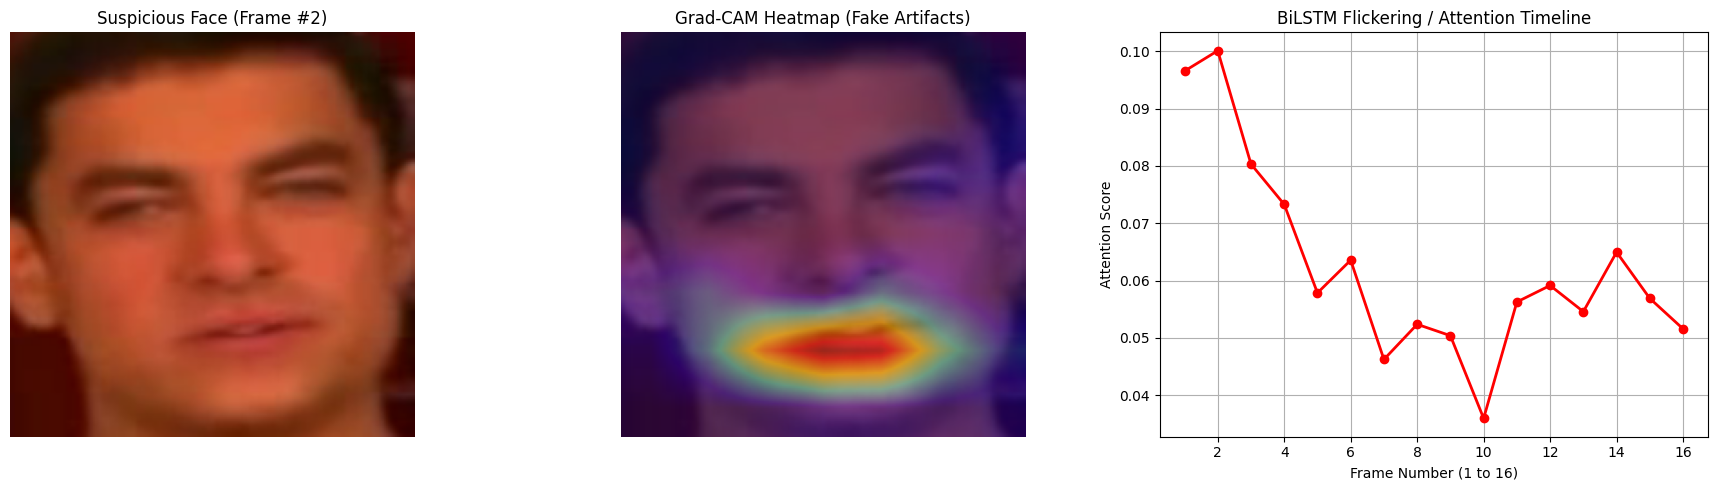

In [32]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the trained model
model = VideoDeepfakeModel().to(device)
model.load_state_dict(torch.load("video_model.pth", map_location=device))
model.eval()

# 2. Select a test video (Taking the first Fake video)
test_video_path = fake_videos[0] 
print(f"Testing XAI on: {test_video_path}")

# 3. Extract sequence and run inference
sequence = extract_face_sequence(test_video_path, num_frames=16) 
input_tensor = sequence.unsqueeze(0).to(device) # Shape: (1, 16, 3, 224, 224)

# Allow gradients to flow for XAI calculation
input_tensor.requires_grad_(True)

# 4. Variables and Hooks to capture data from the CNN backbone
activations = None
gradients = None

def fw_hook(module, input, output):
    global activations
    activations = output

def bw_hook(module, grad_in, grad_out):
    global gradients
    gradients = grad_out[0]

# Attach hooks to the last convolutional layer of ResNeXt-50
target_layer = model.cnn_backbone[-1]
h1 = target_layer.register_forward_hook(fw_hook)
h2 = target_layer.register_full_backward_hook(bw_hook)

# 5. Forward Pass (Temporarily disable cuDNN to allow RNN backprop)
torch.backends.cudnn.enabled = False 
logits, att_weights = model(input_tensor)
fake_prob = torch.sigmoid(logits).item() * 100
att_weights_np = att_weights.squeeze().detach().cpu().numpy()

verdict = "FAKE (Face Manipulated)" if fake_prob > 50 else "AUTHENTIC (Real)"
print(f"Final Verdict: {verdict} | Fake Confidence: {fake_prob:.2f}%")

most_suspicious_idx = int(np.argmax(att_weights_np))
print(f"Most Suspicious Frame: #{most_suspicious_idx + 1}")

# 6. Backward Pass to get Gradients
model.zero_grad()
loss = logits[0, 0] 
loss.backward(retain_graph=True)

torch.backends.cudnn.enabled = True # Re-enable cuDNN
h1.remove()
h2.remove()

# 7. Compute Grad-CAM manually for the most suspicious frame
# Extract exactly the layer data for the selected frame
act = activations[most_suspicious_idx].detach().cpu()
grad = gradients[most_suspicious_idx].detach().cpu()

# Calculate weights and heatmap
weights = torch.mean(grad, dim=(1, 2), keepdim=True)
cam = torch.sum(weights * act, dim=0)
cam = torch.relu(cam).numpy()

# Resize back to 224x224 and normalize
cam = cv2.resize(cam, (224, 224))
cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam) + 1e-8)

# 8. Create Colored Heatmap Overlay
heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0

# De-normalize original face image
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
original_img = sequence[most_suspicious_idx].cpu().numpy().transpose(1, 2, 0)
original_img = std * original_img + mean
original_img = np.clip(original_img, 0, 1)

# Blend heatmap with original face
visualization = 0.4 * heatmap + 0.6 * original_img
visualization = np.clip(visualization, 0, 1)

# 9. Plot XAI Visuals
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(original_img)
axes[0].set_title(f"Suspicious Face (Frame #{most_suspicious_idx + 1})")
axes[0].axis('off')

axes[1].imshow(visualization)
axes[1].set_title("Grad-CAM Heatmap (Fake Artifacts)")
axes[1].axis('off')

axes[2].plot(range(1, 17), att_weights_np, marker='o', color='red', linewidth=2)
axes[2].set_title("BiLSTM Flickering / Attention Timeline")
axes[2].set_xlabel("Frame Number (1 to 16)")
axes[2].set_ylabel("Attention Score")
axes[2].grid(True)

plt.tight_layout()
plt.show()